# Phase 1 — ECG data inspection
Run `00_prepare_data.ipynb` first. This notebook inspects the prepared cohort, then saves the canonical literature-derived subject-group split. Existing Phase 1 assignments remain historical provenance. A/N labels describe status at the beginning of each minute. These examples do not establish a diagnosis. Patient identities remain unverified.

In [1]:
import json
import os
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.model_selection import StratifiedGroupKFold

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
RUN = Path(os.environ.get("APNEA_RUN", str(ROOT / "data/processed/phase1")))
if not RUN.is_absolute():
    RUN = ROOT / RUN
if not (RUN / "manifest.json").exists():
    raise FileNotFoundError("Run 00_prepare_data.ipynb first, or set APNEA_RUN")
manifest = json.loads((RUN / "manifest.json").read_text())
windows = pd.read_parquet(RUN / "windows.parquet")
rr = pd.read_parquet(RUN / "rr.parquet")
peaks = pd.read_parquet(RUN / "peaks.parquet")
quality = pd.read_parquet(RUN / "record_quality.parquet")
rejected = pd.read_parquet(RUN / "rejected_windows.parquet")
print(manifest["split_status"], manifest["independence"])
print("Python:", manifest["python"], "Effective split seed:", manifest.get("effective_split_seed"))
print("Records:", len(quality), "Windows:", len(windows))

unsplit_prepared unassigned; patient identities unverified
Python: 3.12.13 Effective split seed: None
Records: 34 Windows: 16558


## Check sample bounds before splitting
Inspect cohort integrity and class balance before assigning partitions. `c05` was excluded during preparation because it overlaps `c06`.

In [2]:
assert windows["label"].isin([0, 1]).all()
assert (windows.end_sample - windows.start_sample).eq(6000).all()
assert windows.start_sample.ge(0).all()
assert not windows.duplicated(["record_id", "start_sample"]).any()
sizes = quality.set_index("record_id")["n_samples"]
assert windows.end_sample.le(windows.record_id.map(sizes)).all()
display(windows.groupby("label").size().rename("windows").to_frame())
display(
    windows.groupby("record_id").agg(windows=("minute", "size"), apnea_fraction=("label", "mean"))
)

,windows
label,
0,10050
1,6508


,windows,apnea_fraction
record_id,,
a01,489,0.961145
a02,528,0.795455
a03,519,0.473988
a04,492,0.920732
a05,453,0.609272
a06,509,0.404715
a07,510,0.629412
a08,500,0.378000
a09,495,0.769697


## Quality and rejected windows
Quality flags retain complete samples for inspection. Implausible RR intervals are not repaired; they are not necessarily normal-to-normal intervals. Incomplete final minutes and missing labels are excluded explicitly.

In [3]:
display(quality)
display(rejected.groupby(["record_id", "reason"], dropna=False).size().rename("count").to_frame())
display(
    windows.groupby("label")[
        ["quality_flag", "flat_signal", "low_amplitude", "too_few_rr", "suspect_rr", "filter_edge"]
    ].mean()
)
print("RR plausibility fraction:", rr.plausible.mean())
print("Limitations:")
for item in manifest["limitations"]:
    print("-", item)

,record_id,n_samples,n_annotations,n_windows,n_apnea,n_non_apnea,n_peaks,n_suspect_rr,n_flagged_windows,n_rejected_windows,finite_signal
0,a01,2957000,489,489,470,19,29943,2,2,4,True
1,a02,3182000,528,528,420,108,42745,90,44,3,True
2,a03,3135000,519,519,246,273,34119,17,14,4,True
3,a04,2980000,492,492,453,39,31229,3,3,5,True
4,a05,2719500,454,453,276,177,28764,4,3,1,True
5,a06,3058000,510,509,206,303,31138,27,18,1,True
6,a07,3060500,511,510,321,189,37473,3,3,1,True
7,a08,3002500,501,500,189,311,41118,1,1,1,True
8,a09,2988000,495,495,381,114,31577,5,5,3,True
9,a10,3101500,517,516,99,417,32298,5,4,1,True


,,count
record_id,reason,
a01,missing_annotation,4
a02,missing_annotation,3
a03,missing_annotation,4
a04,missing_annotation,5
a05,incomplete_window,1
a06,incomplete_window,1
a07,incomplete_window,1
a08,incomplete_window,1
a09,missing_annotation,3


,quality_flag,flat_signal,low_amplitude,too_few_rr,suspect_rr,filter_edge
label,,,,,,
0,0.048657,0.001592,0.005075,0.011244,0.041692,0.003483
1,0.020590,0.000154,0.000154,0.000307,0.020436,0.000307


RR plausibility fraction: 0.9986796830874429
Limitations:
- Patient IDs unavailable; recording groups do not prove subject independence.
- RR intervals are detected beat intervals, not validated NN intervals.
- Offline zero-phase filtering uses future samples within each recording.
- x evaluation records/labels not used; external evaluation remains separate.


## Normal-labeled and apnea-labeled examples
Each figure shows a full minute plus ten seconds of detail. Check waveform preservation, missed beats, noise, and peak alignment. The same preprocessing applies independently to every recording.

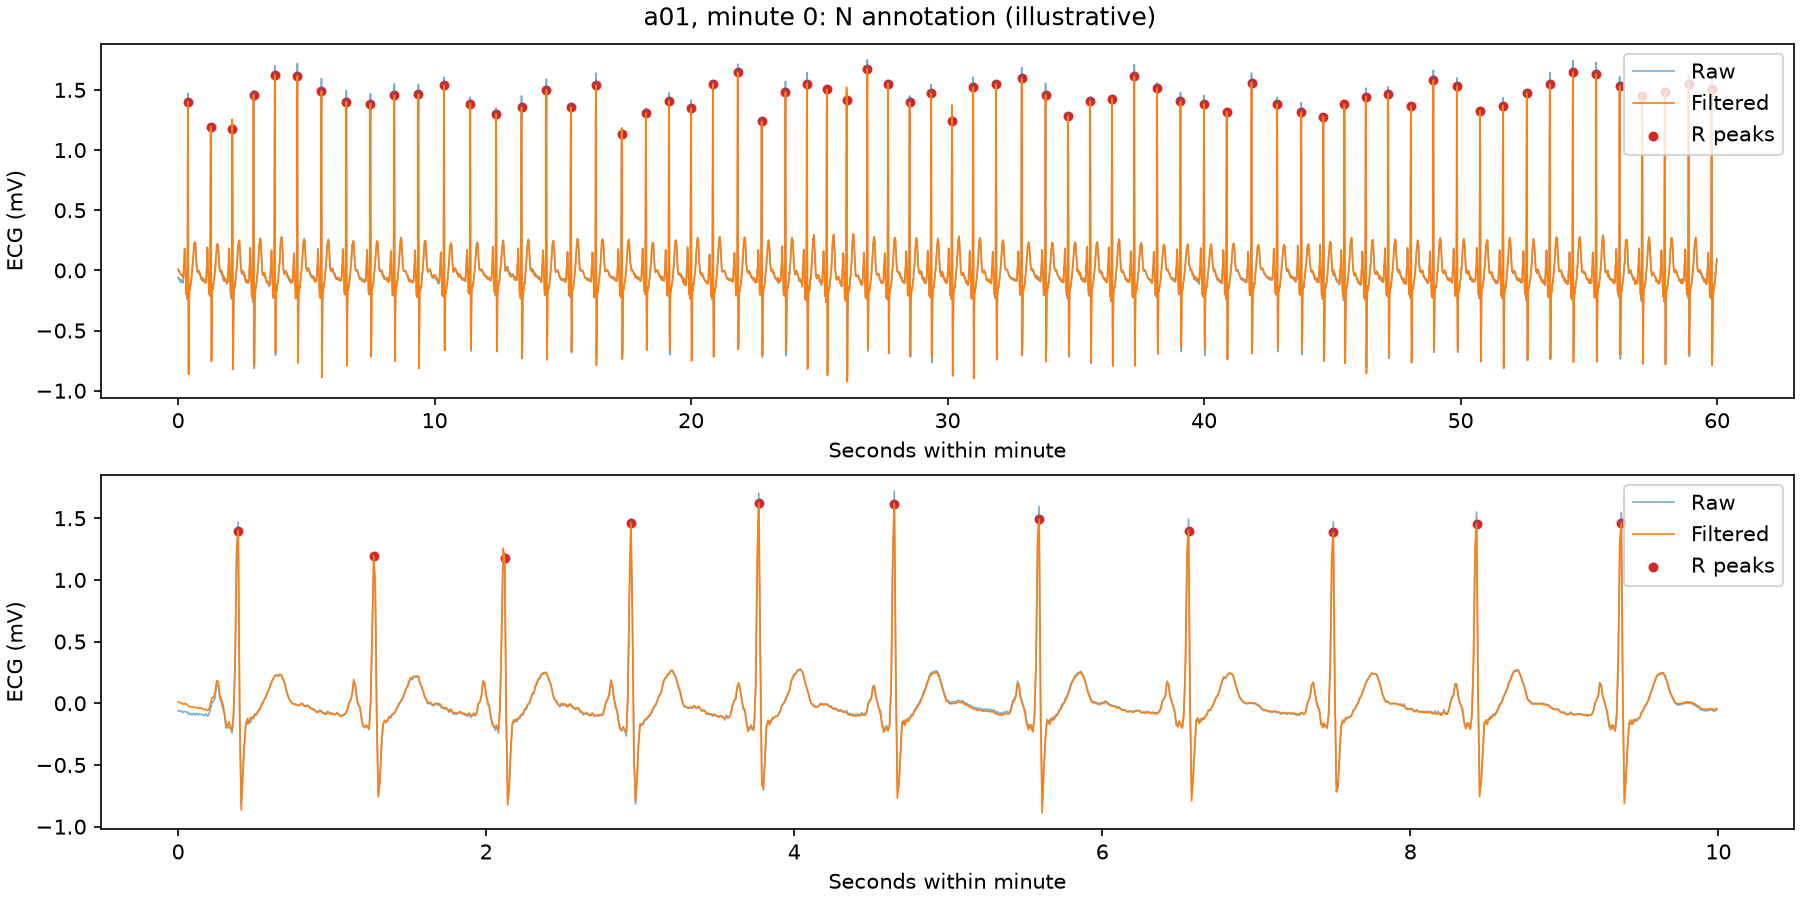

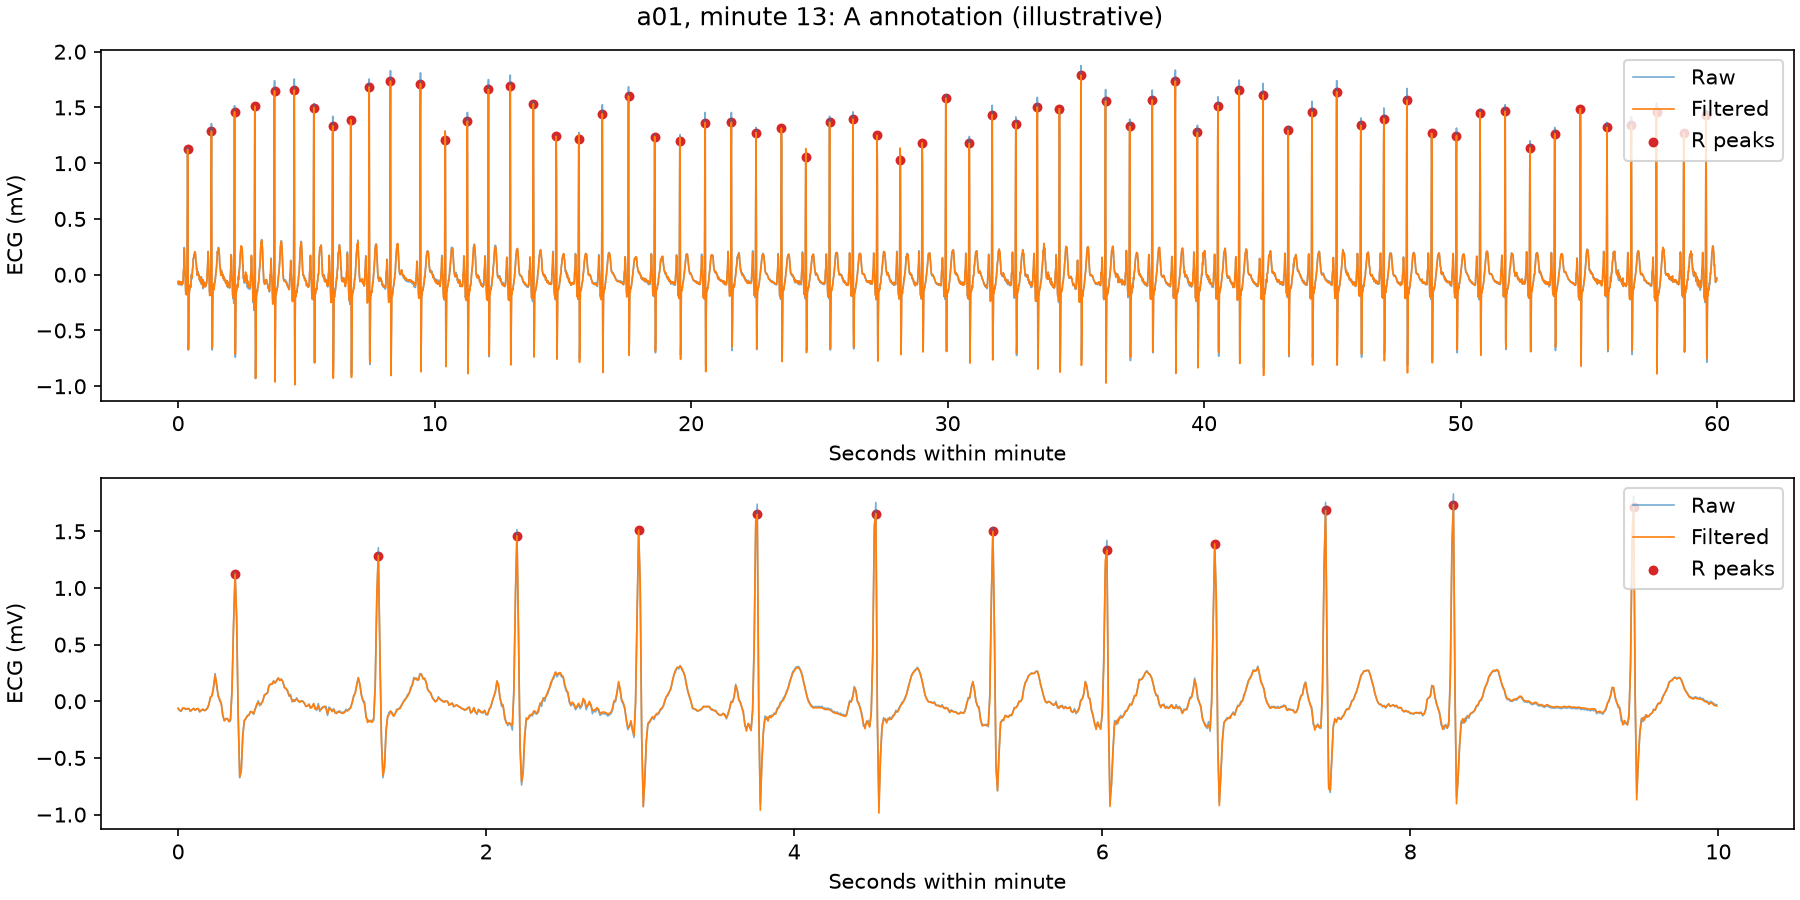

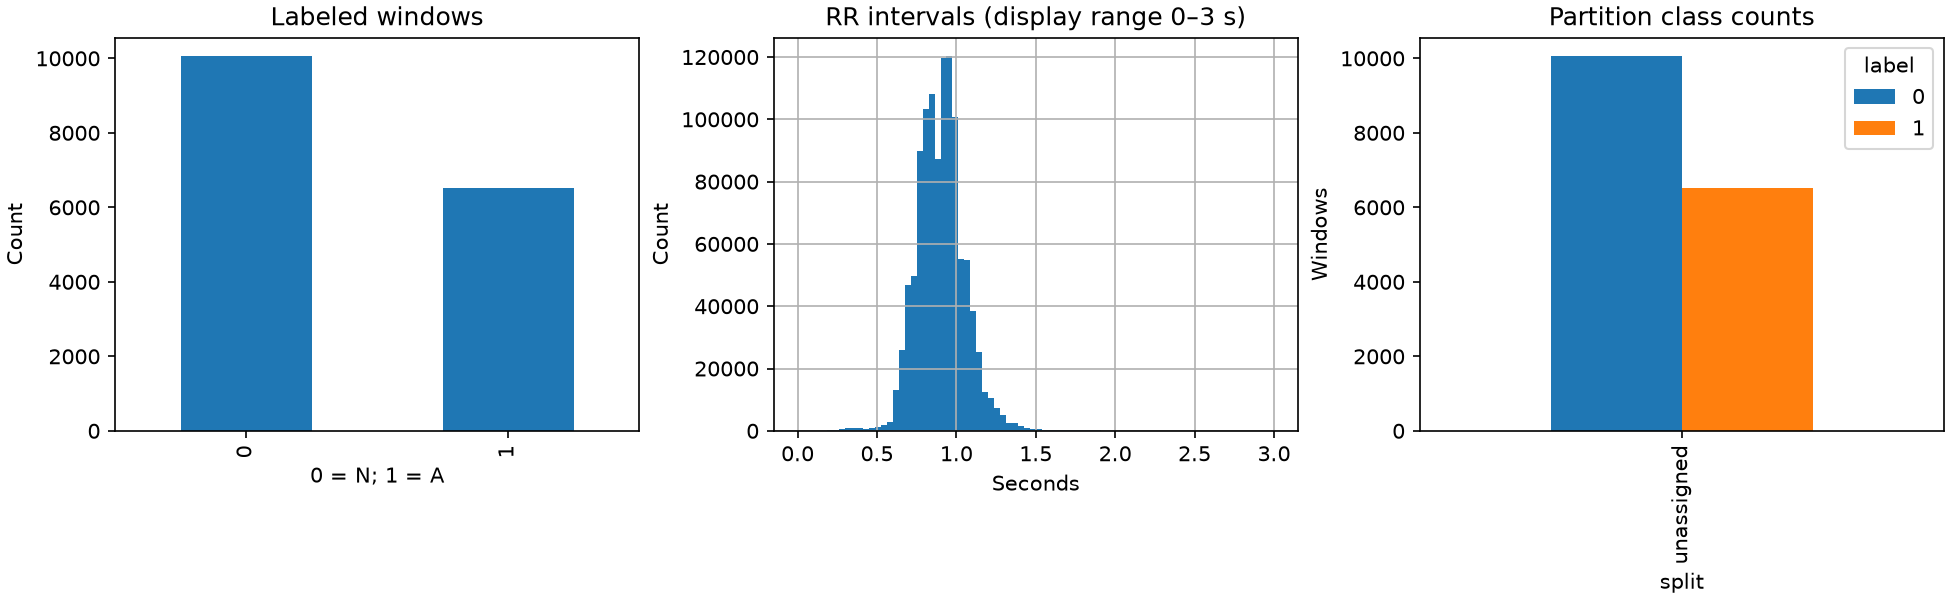

In [4]:
for name in ["example_N.png", "example_A.png", "overview.png"]:
    path = RUN / "figures" / name
    if path.exists():
        display(Image(filename=str(path)))

## Inspect a selected window and its RR intervals
Change the row selection below to inspect another record/minute. Both RR endpoints must lie inside the window for minute-level HRV analysis. Cross-boundary intervals remain available in the record table.

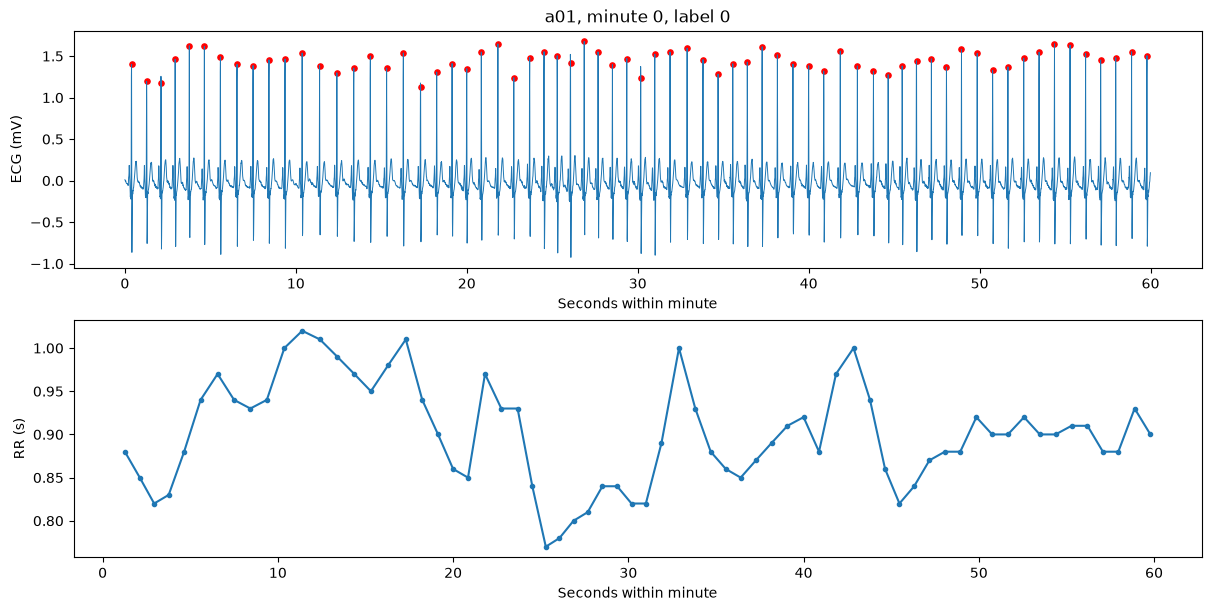

,record_id,start_sample,end_sample,rr_seconds,plausible
0,a01,39,127,0.88,True
1,a01,127,212,0.85,True
2,a01,212,294,0.82,True
3,a01,294,377,0.83,True
4,a01,377,465,0.88,True
5,a01,465,559,0.94,True
6,a01,559,656,0.97,True
7,a01,656,750,0.94,True
8,a01,750,843,0.93,True
9,a01,843,937,0.94,True


In [5]:
row = windows.iloc[0]
start, end = int(row.start_sample), int(row.end_sample)
with np.load(RUN / "waveforms" / f"{row.record_id}.npz") as wave:
    segment = wave["filtered"][start:end]
    fs = float(wave["fs"])
local_peaks = (
    peaks.loc[
        (peaks.record_id == row.record_id) & peaks["sample"].ge(start) & peaks["sample"].lt(end),
        "sample",
    ].to_numpy()
    - start
)
local_rr = rr[(rr.record_id == row.record_id) & rr.start_sample.ge(start) & rr.end_sample.lt(end)]
fig, axes = plt.subplots(2, 1, figsize=(12, 6), constrained_layout=True)
axes[0].plot(np.arange(len(segment)) / fs, segment, lw=0.7)
axes[0].scatter(local_peaks / fs, segment[local_peaks], c="red", s=14)
axes[0].set(
    xlabel="Seconds within minute",
    ylabel="ECG (mV)",
    title=f"{row.record_id}, minute {row.minute}, label {row.label}",
)
axes[1].plot((local_rr.end_sample - start) / fs, local_rr.rr_seconds, marker=".")
axes[1].set(xlabel="Seconds within minute", ylabel="RR (s)")
plt.show()
display(local_rr.head(10))

## Freeze the subject-grouped split after inspection

The learning-set pairings come from [Yeh et al. (2022), Table 1](https://www.mdpi.com/1424-8220/22/2/510). `c05`/`c06` overlap is also documented by PhysioNet. Fold 0 is test, fold 1 validation, and folds 2–4 training. Labels only stratify allocation; model scores do not influence it. Original patient IDs are unavailable, so this remains a literature-derived grouping. Existing historical assignments are retained in `splits.csv`.


In [6]:
SAME_SUBJECT_RECORDS = (
    ("a01", "a14"),
    ("a04", "a12"),
    ("a05", "a10", "a20"),
    ("a07", "a16"),
    ("a08", "a13"),
    ("a09", "a18"),
    ("b02", "b03"),
    ("b04", "c08"),
    ("c02", "c09"),
)
SEED = 67
SPLIT_RUN = Path(os.environ.get("APNEA_SPLIT_RUN", str(ROOT / "data/processed/phase1-grouped")))
if not SPLIT_RUN.is_absolute():
    SPLIT_RUN = ROOT / SPLIT_RUN


def make_subject_splits(windows: pd.DataFrame) -> pd.DataFrame:
    if windows.duplicated(["record_id", "minute"]).any():
        raise ValueError("Duplicate prepared windows")
    mapping = {
        record: f"subj_{records[0]}" for records in SAME_SUBJECT_RECORDS for record in records
    }
    if len(mapping) != sum(map(len, SAME_SUBJECT_RECORDS)):
        raise ValueError("A record belongs to multiple literature groups")
    table = windows[["record_id", "minute", "label", "split"]].copy()
    table["subject_group"] = table.record_id.map(
        lambda record: mapping.get(record, f"subj_{record}")
    )
    fold = np.full(len(table), -1, dtype=int)
    cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    for index, (_, held) in enumerate(cv.split(table, table.label, table.subject_group)):
        fold[held] = index
    if (fold < 0).any():
        raise AssertionError("Every window must be assigned exactly once")
    table["new_split"] = np.where(fold == 0, "test", np.where(fold == 1, "validation", "train"))
    per_record = table[["record_id", "subject_group", "new_split", "split"]].drop_duplicates()
    if len(per_record) != 34 or per_record.record_id.nunique() != 34:
        raise AssertionError("Expected all 34 Phase 1 records")
    if per_record.groupby("subject_group").new_split.nunique().max() != 1:
        raise AssertionError("A subject group crosses partitions")
    if any(set(part.label) != {0, 1} for _, part in table.groupby("new_split")):
        raise AssertionError("Every partition must contain both classes")
    return (
        per_record.rename(columns={"new_split": "split", "split": "phase1_split"})
        .sort_values("record_id")
        .reset_index(drop=True)
    )


if len(windows) < 10000 or windows.record_id.nunique() != 34:
    raise ValueError("Split creation requires the complete prepared cohort")
subject_splits = make_subject_splits(windows)
if SPLIT_RUN.exists():
    saved = pd.read_csv(SPLIT_RUN / "subject_splits.csv")
    if not saved.equals(subject_splits):
        raise ValueError("Existing grouped split differs; choose a new APNEA_SPLIT_RUN")
else:
    SPLIT_RUN.parent.mkdir(parents=True, exist_ok=True)
    with tempfile.TemporaryDirectory(prefix=".phase1-grouped-", dir=SPLIT_RUN.parent) as temporary:
        stage = Path(temporary) / "run"
        stage.mkdir()
        subject_splits.to_csv(stage / "subject_splits.csv", index=False)
        stage.rename(SPLIT_RUN)
display(subject_splits)
grouped = windows.drop(columns="split").merge(
    subject_splits[["record_id", "subject_group", "split"]],
    on="record_id",
    validate="many_to_one",
)
display(grouped.groupby(["split", "label"]).size().unstack(fill_value=0))
print("Subject groups:", subject_splits.subject_group.nunique())

,record_id,subject_group,split,phase1_split
0,a01,subj_a01,train,unassigned
1,a02,subj_a02,validation,unassigned
2,a03,subj_a03,train,unassigned
3,a04,subj_a04,train,unassigned
4,a05,subj_a05,validation,unassigned
5,a06,subj_a06,train,unassigned
6,a07,subj_a07,test,unassigned
7,a08,subj_a08,test,unassigned
8,a09,subj_a09,train,unassigned
9,a10,subj_a05,validation,unassigned


label,0,1
split,,
test,2301,1080
train,5351,3939
validation,2398,1489


Subject groups: 24


## Next phase
Run `02_feature_ablation.ipynb` with the saved grouped split, then `03_waveform_cnn.ipynb` and `04_optimization_evaluation.ipynb`.